In [26]:
import kagglehub
import pandas as pd
path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/banksim1


Training XGBoost model...
[0]	validation_0-logloss:0.60302
[20]	validation_0-logloss:0.09241
[40]	validation_0-logloss:0.04242
[60]	validation_0-logloss:0.03540
[80]	validation_0-logloss:0.03417
[100]	validation_0-logloss:0.03362
[120]	validation_0-logloss:0.03320
[140]	validation_0-logloss:0.03265
[160]	validation_0-logloss:0.03224
[180]	validation_0-logloss:0.03178
[200]	validation_0-logloss:0.03155
[220]	validation_0-logloss:0.03125
[240]	validation_0-logloss:0.03087
[260]	validation_0-logloss:0.03052
[280]	validation_0-logloss:0.03031
[300]	validation_0-logloss:0.03011
[320]	validation_0-logloss:0.02989
[340]	validation_0-logloss:0.02959
[360]	validation_0-logloss:0.02940
[380]	validation_0-logloss:0.02916
[400]	validation_0-logloss:0.02902
[420]	validation_0-logloss:0.02875
[440]	validation_0-logloss:0.02860
[460]	validation_0-logloss:0.02839
[480]	validation_0-logloss:0.02818
[499]	validation_0-logloss:0.02810

Finding optimal threshold...
Optimal threshold: 0.8429

Final Model P

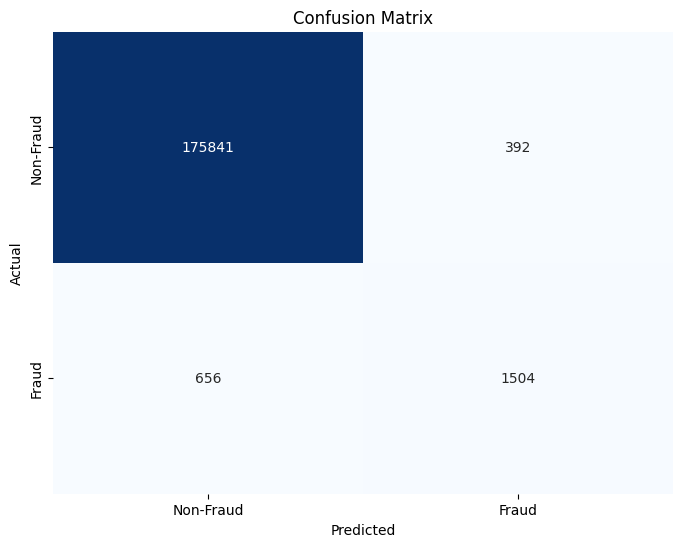

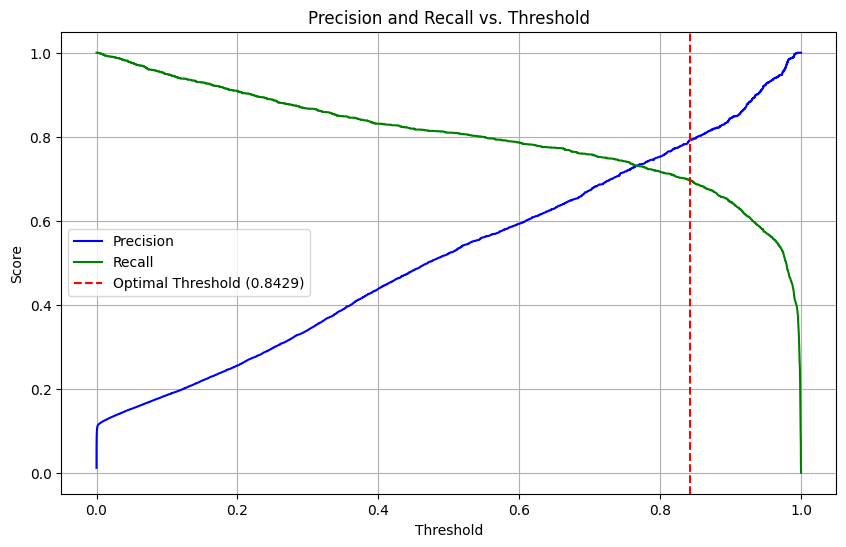

<ipython-input-28-2740738087>:95: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


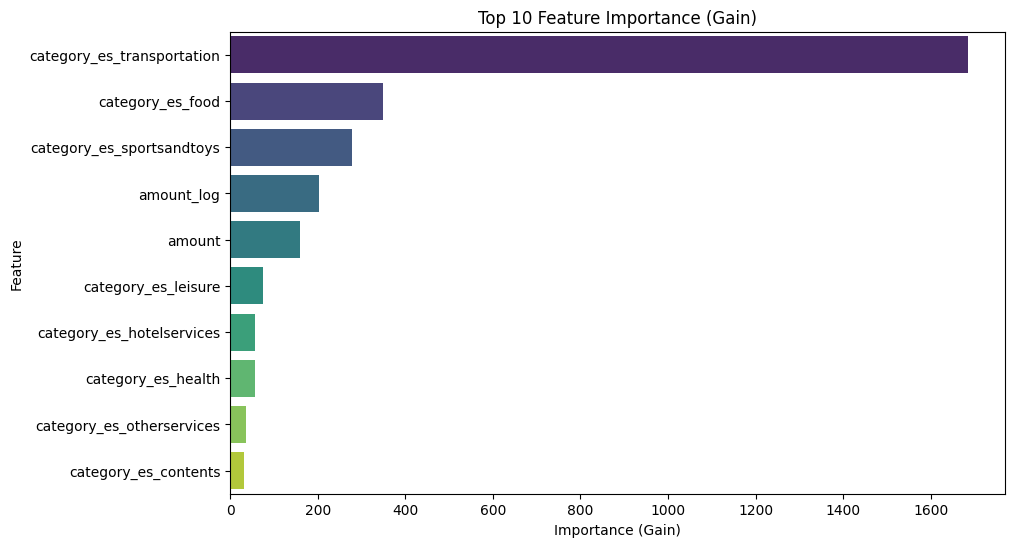

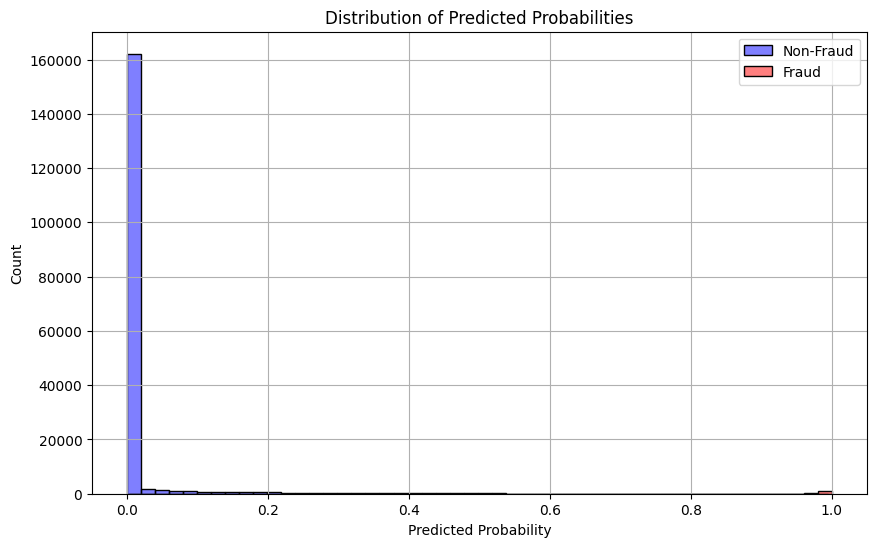


Saving model pipeline...
Model saved as fraud_model.pkl, fraud_model.json, and scaler.pkl


In [ ]:
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve
from sklearn.preprocessing import StandardScaler
import joblib
import json
import matplotlib.pyplot as plt
import seaborn as sns


def custom_objective(y_true, y_pred):
    fn_weight = 10.0
    pred = 1.0 / (1.0 + np.exp(-y_pred))
    grad = np.where(y_true == 1, -fn_weight * (1.0 - pred), pred)
    hess = np.where(y_true == 1, fn_weight * pred * (1.0 - pred), pred * (1.0 - pred))
    return grad, hess


def load_and_preprocess(filepath):
    df = pd.read_csv(filepath, quotechar='"')
    str_cols = ['customer', 'merchant', 'category', 'gender', 'zipcodeOri', 'zipMerchant']
    for col in str_cols:
        df[col] = df[col].str.replace("'", "")
    df['amount_log'] = np.log(df['amount'] + 1e-6)
    df['hour'] = df['step'] % 24
    df = pd.get_dummies(df, columns=['category', 'gender', 'age'])
    return df


def train_xgboost_model(X_train, y_train):
    model = xgb.XGBClassifier(
        objective=custom_objective,
        eval_metric='logloss',
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=1,
        min_child_weight=10,
        seed=42,
        n_estimators=500
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_train, y_train)],
        verbose=20
    )
    return model


def find_optimal_threshold(model, X_test, y_test):
    y_proba = 1.0 / (1.0 + np.exp(-model.predict(X_test, output_margin=True)))
    precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-9)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    return optimal_threshold, precision, recall, thresholds


def plot_confusion_matrix(y_test, y_pred):
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'])
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.savefig('confusion_matrix.png')
    plt.show()


def plot_precision_recall_curve(precision, recall, thresholds, optimal_threshold):
    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, precision[:-1], label='Precision', color='blue')
    plt.plot(thresholds, recall[:-1], label='Recall', color='green')
    plt.axvline(x=optimal_threshold, color='r', linestyle='--', label=f'Optimal Threshold ({optimal_threshold:.4f})')
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.title('Precision and Recall vs. Threshold')
    plt.legend()
    plt.grid(True)
    plt.savefig('precision_recall_vs_threshold.png')
    plt.show()


def plot_feature_importance(model, features, top_n=10):
    importance = model.get_booster().get_score(importance_type='gain')
    importance_df = pd.DataFrame({
        'Feature': list(importance.keys()),
        'Importance': list(importance.values())
    }).sort_values(by='Importance', ascending=False).head(top_n)
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
    plt.title(f'Top {top_n} Feature Importance (Gain)')
    plt.xlabel('Importance (Gain)')
    plt.ylabel('Feature')
    plt.savefig('feature_importance.png')
    plt.show()


def plot_probability_distribution(y_test, y_proba):
    plt.figure(figsize=(10, 6))
    sns.histplot(y_proba[y_test == 0], bins=50, color='blue', alpha=0.5, label='Non-Fraud')
    sns.histplot(y_proba[y_test == 1], bins=50, color='red', alpha=0.5, label='Fraud')
    plt.xlabel('Predicted Probability')
    plt.ylabel('Count')
    plt.title('Distribution of Predicted Probabilities')
    plt.legend()
    plt.grid(True)
    plt.savefig('probability_distribution.png')
    plt.show()


def save_model_pipeline(model, features, threshold, file_prefix='fraud_model'):
    model.save_model(f'{file_prefix}.json')
    pipeline = {
        'model': model,
        'features': features,
        'threshold': threshold
    }
    joblib.dump(pipeline, f'{file_prefix}.pkl')
    metadata = {
        'features': features,
        'threshold': float(threshold)
    }
    with open(f'{file_prefix}_metadata.json', 'w') as f:
        json.dump(metadata, f)


if __name__ == '__main__':
    # path = '.'  # Set this to the directory containing the CSV if needed
    df = load_and_preprocess(path + '/bs140513_032310.csv')
    features = ['amount', 'amount_log', 'hour'] + \
               [col for col in df.columns if col.startswith(('category_', 'gender_', 'age_'))]
    X = df[features]
    y = df['fraud']
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )
    scaler = StandardScaler()
    X_train[['amount', 'amount_log', 'hour']] = scaler.fit_transform(X_train[['amount', 'amount_log', 'hour']])
    X_test[['amount', 'amount_log', 'hour']] = scaler.transform(X_test[['amount', 'amount_log', 'hour']])
    print("Training XGBoost model...")
    model = train_xgboost_model(X_train, y_train)
    print("\nFinding optimal threshold...")
    threshold, precision, recall, thresholds = find_optimal_threshold(model, X_test, y_test)
    print(f"Optimal threshold: {threshold:.4f}")
    y_proba = 1.0 / (1.0 + np.exp(-model.predict(X_test, output_margin=True)))
    y_pred = (y_proba >= threshold).astype(int)
    print("\nFinal Model Performance:")
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nGenerating visualizations...")
    plot_confusion_matrix(y_test, y_pred)
    plot_precision_recall_curve(precision, recall, thresholds, threshold)
    plot_feature_importance(model, features)
    plot_probability_distribution(y_test, y_proba)
    print("\nSaving model pipeline...")
    save_model_pipeline(model, features, threshold)
    joblib.dump(scaler, 'scaler.pkl')
    print("Model saved as fraud_model.pkl, fraud_model.json, and scaler.pkl")

Prediction Results:
  customer  amount               category  fraud_probability  fraud_prediction
0   C12345   85.20  es_barsandrestaurants           0.085252                 0
1   C67890  150.00              es_health           0.277336                 0
2   C13579   32.50      es_transportation           0.000028                 0
3   C24680  200.75             es_fashion           0.631589                 0
4   C35791   45.30             es_leisure           0.549992                 0


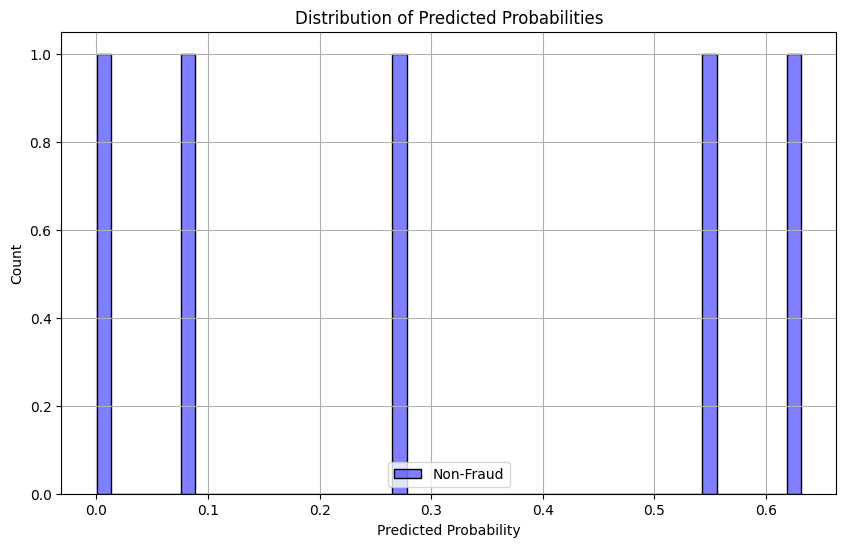

<ipython-input-35-2404861454>:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fraud_Prediction', y='Count', data=summary, palette='viridis')


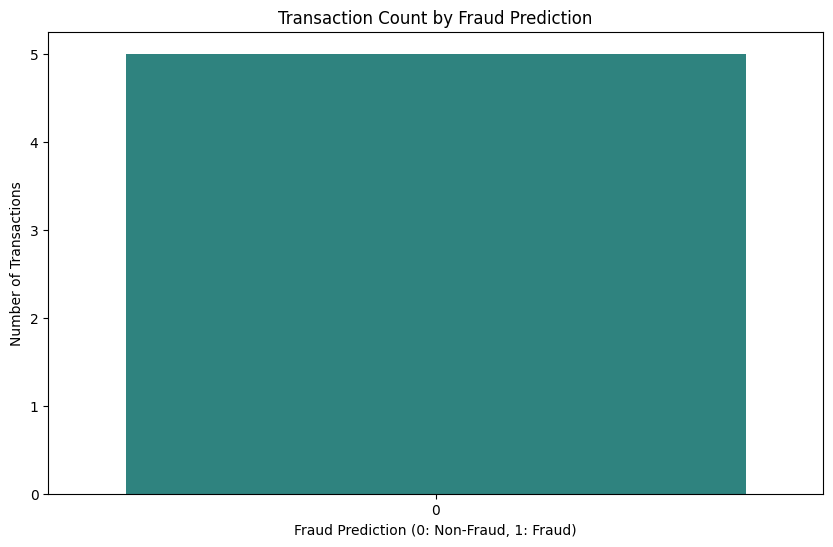

In [ ]:
import numpy as np
import joblib


def preprocess_new_data(new_data):
    new_data['amount_log'] = np.log(new_data['amount'] + 1e-6)
    new_data['hour'] = new_data['step'] % 24

    categories = [
        'es_barsandrestaurants', 'es_health', 'es_transportation', 'es_food',
        'es_contents', 'es_fashion', 'es_home', 'es_hotelservices', 'es_hyper',
        'es_leisure', 'es_otherservices', 'es_sportsandtoys', 'es_tech',
        'es_travel', 'es_wellnessandbeauty'
    ]
    genders = ['M', 'F', 'E', 'U']
    ages = ['0', '1', '2', '3', '4', '5', '6', 'U']

    for cat in categories:
        new_data[f'category_{cat}'] = (new_data['category'] == cat).astype(int)
    for gender in genders:
        new_data[f'gender_{gender}'] = (new_data['gender'] == gender).astype(int)
    for age in ages:
        new_data[f'age_{age}'] = (new_data['age'] == age).astype(int)

    return new_data


def plot_probability_distribution(probas, predictions):
    plt.figure(figsize=(10, 6))
    sns.histplot(probas[predictions == 0], bins=50, color='blue', alpha=0.5, label='Non-Fraud')
    sns.histplot(probas[predictions == 1], bins=50, color='red', alpha=0.5, label='Fraud')
    plt.xlabel('Predicted Probability')
    plt.ylabel('Count')
    plt.title('Distribution of Predicted Probabilities')
    plt.legend()
    plt.grid(True)
    plt.savefig('demo_probability_distribution.png')
    plt.show()


def plot_prediction_summary(new_data):
    summary = new_data.groupby('fraud_prediction')['amount'].agg(['count', 'mean', 'sum']).reset_index()
    summary.columns = ['Fraud_Prediction', 'Count', 'Avg_Amount', 'Total_Amount']
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Fraud_Prediction', y='Count', data=summary, palette='viridis')
    plt.title('Transaction Count by Fraud Prediction')
    plt.xlabel('Fraud Prediction (0: Non-Fraud, 1: Fraud)')
    plt.ylabel('Number of Transactions')
    plt.savefig('demo_prediction_summary.png')
    plt.show()


def demo_fraud_model(new_data):
    with open('fraud_model_metadata.json') as f:
        metadata = json.load(f)
    threshold = metadata['threshold']
    features = metadata['features']

    scaler = joblib.load('scaler.pkl')

    model = xgb.XGBClassifier()
    model.load_model('fraud_model.json')

    new_data = preprocess_new_data(new_data)

    new_data_full = pd.DataFrame(0, index=new_data.index, columns=features)
    for col in new_data.columns:
        if col in features:
            new_data_full[col] = new_data[col]

    num_features = ['amount', 'amount_log', 'hour']
    new_data_full[num_features] = scaler.transform(new_data_full[num_features])

    probas = model.predict_proba(new_data_full[features])[:, 1]
    predictions = (probas >= threshold).astype(int)

    new_data['fraud_probability'] = probas
    new_data['fraud_prediction'] = predictions

    print("Prediction Results:")
    print(new_data[['customer', 'amount', 'category', 'fraud_probability', 'fraud_prediction']])

    plot_probability_distribution(probas, predictions)
    plot_prediction_summary(new_data)

    return new_data


if __name__ == '__main__':
    new_data = pd.DataFrame({
        'step': [345, 678, 901, 1000, 1200],
        'customer': ['C12345', 'C67890', 'C13579', 'C24680', 'C35791'],
        'age': ['3', '2', '1', '4', 'U'],
        'gender': ['M', 'F', 'M', 'F', 'E'],
        'category': ['es_barsandrestaurants', 'es_health', 'es_transportation', 'es_fashion', 'es_leisure'],
        'amount': [85.20, 150.00, 32.50, 200.75, 45.30]
    })

    results = demo_fraud_model(new_data)